# 01_eda_v2 — `01_eda.ipynb` 수정본

원본 `C:\t_project_1_1\01_eda.ipynb`은 원본 CSV 전체(260,601행)를 읽었습니다. 여기에는 팀 `final_holdout` 52,121행의 정답도 포함됩니다.
팀 규칙상 홀드아웃의 입력-정답 관계는 탐색하지 않으므로, 이 복사본은 **팀 development 208,480행만** 읽습니다.

분석 코드는 원본과 같고, 바뀐 것은 데이터 경로와 저장 경로뿐입니다. 그래서 건수와 비율 숫자는 원본과 다르게 나옵니다.

In [ ]:
# [v2] 팀 development 데이터만 사용 (final_holdout 제외)
from pathlib import Path

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "preprocess.py").exists())
DEV_CSV = REPO / "data" / "development.csv"   # 원본 CSV에서 팀 홀드아웃 52,121행을 뺀 208,480행
OUT_DIR = REPO / "outputs" / "t_project_v2" / "01_eda"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("데이터:", DEV_CSV)
print("저장 폴더:", OUT_DIR)

데이터: C:\Users\jhj31\project_1\earthquake\data\development.csv
저장 폴더: C:\Users\jhj31\project_1\earthquake\outputs\t_project_v2\01_eda


# 01. EDA — 네팔 지진 건물 피해 데이터

**목적** 모델링 전에 데이터의 구조·품질·신호를 확인한다.

**이 노트북이 지키는 원칙 (컬럼정의서 기준)**
1. 익명화 코드(`n`, `o`, `t` 등)에 임의의 의미를 부여하지 않는다.
2. `geo_level_*`는 명목형이다. 숫자 크기에 거리·순위 의미가 없다.
3. `area_percentage`, `height_percentage`는 정규화 값이다. ㎡·m로 환산하지 않는다.
4. 이진 플래그의 `0`은 "비해당"이지 결측이 아니다.
5. **이상치는 이 노트북에서 제거하지 않는다.** 탐지하고 판단 근거만 기록한다.
6. 상부구조 재료는 복수 선택이 가능하다. 단일 범주형으로 합치지 않는다.

In [2]:
# ============================================================
# §0. 환경 설정
# ============================================================
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

DATA_PATH = DEV_CSV  # [v2] 팀 development
FIG_DIR = OUT_DIR / "figures"  # [v2]
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42


def set_korean_font():
    """OS별 한글 폰트를 자동 탐색한다. 없으면 경고만 하고 진행한다."""
    candidates = [
        "Malgun Gothic",      # Windows
        "AppleGothic",        # macOS
        "NanumGothic",        # Linux (apt install fonts-nanum)
        "NanumBarunGothic",
        "Noto Sans CJK KR",
        "Noto Sans CJK JP",
    ]
    installed = {f.name for f in fm.fontManager.ttflist}
    for name in candidates:
        if name in installed:
            plt.rcParams["font.family"] = name
            plt.rcParams["axes.unicode_minus"] = False
            print(f"[폰트] '{name}' 적용")
            return name
    print("[폰트] 한글 폰트를 찾지 못했습니다. 그래프 한글이 깨질 수 있습니다.")
    print("       Linux: sudo apt install fonts-nanum  /  이후 커널 재시작")
    plt.rcParams["axes.unicode_minus"] = False
    return None


set_korean_font()
sns.set_theme(style="whitegrid", rc={"font.family": plt.rcParams["font.family"]})
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)


def save_fig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"[저장] {path}")

[폰트] 'Malgun Gothic' 적용


In [3]:
# ============================================================
# §1. 데이터 로드 및 구조 확인
# ============================================================
df = pd.read_csv(DATA_PATH)

ID_COL = "building_id"
TARGET = "damage_grade"

GEO_COLS = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]
NUM_COLS = ["count_floors_pre_eq", "age", "area_percentage",
            "height_percentage", "count_families"]
CAT_COLS = ["land_surface_condition", "foundation_type", "roof_type",
            "ground_floor_type", "other_floor_type", "position",
            "plan_configuration", "legal_ownership_status"]
SUPER_COLS = [c for c in df.columns if c.startswith("has_superstructure")]
SEC_COLS = [c for c in df.columns if c.startswith("has_secondary_use")]
FEATURE_COLS = GEO_COLS + NUM_COLS + CAT_COLS + SUPER_COLS + SEC_COLS

print(f"행 수   : {df.shape[0]:,}")
print(f"컬럼 수 : {df.shape[1]}")
print(f"메모리  : {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
print()
print("[컬럼 그룹]")
for label, cols in [("지역 코드", GEO_COLS), ("수치형", NUM_COLS), ("범주형", CAT_COLS),
                    ("상부구조 재료(이진)", SUPER_COLS), ("부가 용도(이진)", SEC_COLS)]:
    print(f"  {label:20s} {len(cols):2d}개")
print(f"  {'입력 X 합계':20s} {len(FEATURE_COLS):2d}개")
print(f"  {'ID / 타깃 Y':20s}  {ID_COL} / {TARGET}")

# 컬럼 누락 검증 — 분류되지 않은 컬럼이 있으면 즉시 중단
unclassified = set(df.columns) - set(FEATURE_COLS) - {ID_COL, TARGET}
assert not unclassified, f"분류되지 않은 컬럼: {unclassified}"
assert len(FEATURE_COLS) == 38, f"입력 변수 수가 38이 아님: {len(FEATURE_COLS)}"
print("\n분류 검증 통과 (입력 38 + ID 1 + 타깃 1 = 40)")

행 수   : 208,480
컬럼 수 : 40
메모리  : 130.4 MB

[컬럼 그룹]
  지역 코드                 3개
  수치형                   5개
  범주형                   8개
  상부구조 재료(이진)          11개
  부가 용도(이진)            11개
  입력 X 합계              38개
  ID / 타깃 Y             building_id / damage_grade

분류 검증 통과 (입력 38 + ID 1 + 타깃 1 = 40)


In [4]:
df.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,4,30,266,1224,1,25,5,2,t,r,n,f,j,s,d,0,1,0,0,0,0,0,0,0,0,0,v,0,0,0,0,0,0,0,0,0,0,0,0,2
1,8,17,409,12182,2,0,13,7,t,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
2,12,17,716,7056,2,5,12,6,o,r,q,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,16,4,651,105,2,80,5,4,n,r,n,f,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,25,26,1132,6645,2,0,6,6,t,w,n,f,x,s,d,0,0,0,0,0,0,1,0,0,0,0,a,1,0,0,0,0,0,0,0,0,0,0,0,1


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 208480 entries, 0 to 208479
Data columns (total 40 columns):
 #   Column                                  Non-Null Count   Dtype
---  ------                                  --------------   -----
 0   building_id                             208480 non-null  int64
 1   geo_level_1_id                          208480 non-null  int64
 2   geo_level_2_id                          208480 non-null  int64
 3   geo_level_3_id                          208480 non-null  int64
 4   count_floors_pre_eq                     208480 non-null  int64
 5   age                                     208480 non-null  int64
 6   area_percentage                         208480 non-null  int64
 7   height_percentage                       208480 non-null  int64
 8   land_surface_condition                  208480 non-null  str  
 9   foundation_type                         208480 non-null  str  
 10  roof_type                               208480 non-null  str  
 11  ground_floo

                  건수  비율(%)
damage_grade               
1              20099   9.64
2             118607  56.89
3              69774  33.47

최다/최소 클래스 비율 = 5.90 : 1
모두 최빈값(2)으로 찍었을 때의 정확도 = 0.5689  ← 베이스라인 하한


[저장] C:\Users\jhj31\project_1\earthquake\outputs\t_project_v2\01_eda\figures\target_distribution.png


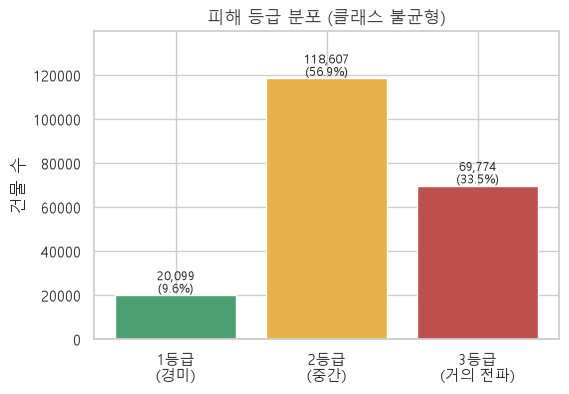

In [6]:
# ============================================================
# §2. 타깃 분포 — 클래스 불균형 확인
# ============================================================
GRADE_LABEL = {1: "1등급\n(경미)", 2: "2등급\n(중간)", 3: "3등급\n(거의 전파)"}

vc = df[TARGET].value_counts().sort_index()
target_dist = pd.DataFrame({"건수": vc, "비율(%)": (vc / len(df) * 100).round(2)})
print(target_dist.to_string())
print(f"\n최다/최소 클래스 비율 = {vc.max() / vc.min():.2f} : 1")
print(f"모두 최빈값({vc.idxmax()})으로 찍었을 때의 정확도 = {vc.max() / len(df):.4f}  ← 베이스라인 하한")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([GRADE_LABEL[i] for i in vc.index], vc.values,
              color=["#4C9F70", "#E8B04B", "#C0504D"])
for b, v in zip(bars, vc.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v/len(df)*100:.1f}%)",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("건물 수")
ax.set_title("피해 등급 분포 (클래스 불균형)")
ax.set_ylim(0, vc.max() * 1.18)
save_fig(fig, "target_distribution")
plt.show()

In [7]:
# ============================================================
# §3. 결측치 점검
# ============================================================
print("=" * 60)
print("3-1. 일반 결측치 (NaN)")
print("=" * 60)
na = df.isna().sum()
print(f"전체 결측 셀 수 : {na.sum()}")
if na.sum() == 0:
    print("→ NaN 형태의 결측은 없다. 결측 대치(imputation) 단계는 불필요.")
else:
    print(na[na > 0].to_string())

3-1. 일반 결측치 (NaN)
전체 결측 셀 수 : 0
→ NaN 형태의 결측은 없다. 결측 대치(imputation) 단계는 불필요.


In [8]:
print("=" * 60)
print("3-2. 의미론적 결측 후보 — age = 995")
print("=" * 60)
ages = np.sort(df["age"].unique())
print(f"age 고유값 {len(ages)}개: {ages.tolist()}")
gaps = set(np.diff(ages[ages <= 200]).tolist())
print(f"\n200 이하 값들의 간격 집합 = {gaps}")
print("→ 0~200이 5년 단위로 이미 구간화돼 있고, 995만 이 격자를 벗어난다.")
print(f"   995 건수 = {(df['age'] == 995).sum():,}  ({(df['age'] == 995).mean()*100:.2f}%)")
print(f"   100 < age < 995 건수 = {((df['age'] > 100) & (df['age'] != 995)).sum():,}")

# 995가 '최고령 건물'인지 '코드값'인지 — 피해 프로필로 판별
print("\n[age 구간별 피해 프로필]")
bins = [(0, 0, "0년(신축)"), (5, 50, "5~50년"), (55, 95, "55~95년"),
        (100, 145, "100~145년"), (150, 200, "150~200년")]
rows = []
for lo, hi, label in bins:
    g = df.loc[df["age"].between(lo, hi), TARGET]
    rows.append({"구간": label, "건수": len(g), "1등급%": round((g == 1).mean()*100, 1),
                 "2등급%": round((g == 2).mean()*100, 1), "3등급%": round((g == 3).mean()*100, 1),
                 "평균등급": round(g.mean(), 3)})
g = df.loc[df["age"] == 995, TARGET]
rows.append({"구간": "age=995", "건수": len(g), "1등급%": round((g == 1).mean()*100, 1),
             "2등급%": round((g == 2).mean()*100, 1), "3등급%": round((g == 3).mean()*100, 1),
             "평균등급": round(g.mean(), 3)})
g = df[TARGET]
rows.append({"구간": "── 전체 평균", "건수": len(g), "1등급%": round((g == 1).mean()*100, 1),
             "2등급%": round((g == 2).mean()*100, 1), "3등급%": round((g == 3).mean()*100, 1),
             "평균등급": round(g.mean(), 3)})
age_profile = pd.DataFrame(rows)
print(age_profile.to_string(index=False))
print("""
[판단] 진짜 노후 건물(100년 이상)은 1등급 비율이 1% 내외다.
       age=995 집단은 1등급 비율이 전체 평균보다 오히려 높다.
       → '995년 된 건물'이 아니라 결측/미상을 나타내는 코드값일 가능성이 크다.
       → 전처리 단계 권장: age를 995로 두지도, 100으로 캡하지도 말고
         (a) age_is_sentinel 플래그 생성 (b) age는 NaN 처리
         (트리 계열 모델은 NaN을 네이티브로 분기하므로 대치 불필요)
       → 이 노트북에서는 변환하지 않는다. 전처리 노트북에서 실험으로 비교할 것.
""")

3-2. 의미론적 결측 후보 — age = 995
age 고유값 41개: [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150, 155, 160, 165, 170, 175, 180, 190, 195, 200, 995]

200 이하 값들의 간격 집합 = {10, 5}
→ 0~200이 5년 단위로 이미 구간화돼 있고, 995만 이 격자를 벗어난다.
   995 건수 = 1,125  (0.54%)
   100 < age < 995 건수 = 591

[age 구간별 피해 프로필]
      구간     건수  1등급%  2등급%  3등급%  평균등급
  0년(신축)  20847  27.6  49.0  23.4 1.957
   5~50년 173046   8.1  57.6  34.4 2.263
  55~95년  11788   1.6  59.6  38.8 2.372
100~145년   1446   0.9  65.9  33.2 2.323
150~200년    228   0.9  66.2  32.9 2.320
 age=995   1125  13.1  58.8  28.2 2.151
── 전체 평균 208480   9.6  56.9  33.5 2.238

[판단] 진짜 노후 건물(100년 이상)은 1등급 비율이 1% 내외다.
       age=995 집단은 1등급 비율이 전체 평균보다 오히려 높다.
       → '995년 된 건물'이 아니라 결측/미상을 나타내는 코드값일 가능성이 크다.
       → 전처리 단계 권장: age를 995로 두지도, 100으로 캡하지도 말고
         (a) age_is_sentinel 플래그 생성 (b) age는 NaN 처리
         (트리 계열 모델은 NaN을 네이티브로 분기하므로 대치 불필요)
       → 이 노트북에서는 변환하지 않는다.

In [9]:
print("=" * 60)
print("3-3. 0을 결측으로 오인하기 쉬운 변수")
print("=" * 60)
zero_check = pd.DataFrame({
    "0인 건수": [(df[c] == 0).sum() for c in ["age", "count_families"]],
    "비율(%)": [round((df[c] == 0).mean()*100, 2) for c in ["age", "count_families"]],
}, index=["age", "count_families"])
print(zero_check.to_string())
print("\n[age=0] 신축 또는 1년 미만의 반올림일 수 있다. 결측으로 단정 금지.")
print("[count_families=0] 빈집·창고일 수 있다. 결측으로 단정 금지.")
print("\ncount_families=0 집단의 피해 분포:")
print(df.groupby(df["count_families"].eq(0))[TARGET]
        .value_counts(normalize=True).unstack().round(3)
        .rename(index={False: "가구≥1", True: "가구=0"}).to_string())

3-3. 0을 결측으로 오인하기 쉬운 변수
                0인 건수  비율(%)
age             20847   10.0
count_families  16683    8.0

[age=0] 신축 또는 1년 미만의 반올림일 수 있다. 결측으로 단정 금지.
[count_families=0] 빈집·창고일 수 있다. 결측으로 단정 금지.

count_families=0 집단의 피해 분포:


damage_grade        1      2      3
count_families                     
가구≥1            0.089  0.571  0.339
가구=0            0.176  0.542  0.281


In [10]:
# ============================================================
# §4. 중복치 점검
# ============================================================
print("=" * 60)
print("4-1. 식별자 중복")
print("=" * 60)
print(f"{ID_COL} 중복 건수 : {df[ID_COL].duplicated().sum()}")
print("→ 0이면 한 건물이 한 번만 등장한다. 행 단위 중복 제거 불필요.")

4-1. 식별자 중복
building_id 중복 건수 : 0
→ 0이면 한 건물이 한 번만 등장한다. 행 단위 중복 제거 불필요.


In [11]:
print("=" * 60)
print("4-2. 속성 중복 (building_id 제외 전 컬럼 동일)")
print("=" * 60)
dup_mask = df[FEATURE_COLS + [TARGET]].duplicated(keep=False)
print(f"타깃까지 포함해 완전히 같은 행 : {dup_mask.sum():,}건")

feat_dup_mask = df[FEATURE_COLS].duplicated(keep=False)
print(f"입력 38개만 같은 행           : {feat_dup_mask.sum():,}건 "
      f"({feat_dup_mask.mean()*100:.2f}%)")
print("""
[판단] 이 데이터에서 '속성이 같다'는 것은 같은 건물이 아니라
       '구조·지역·재료가 동일한 다른 건물'을 뜻한다.
       예: 같은 마을의 2층 진흙모르타르석재 주택 여러 채.
       → 삭제하면 그 유형의 빈도 정보가 사라진다. 제거하지 않는다.
""")

4-2. 속성 중복 (building_id 제외 전 컬럼 동일)


타깃까지 포함해 완전히 같은 행 : 14,962건


입력 38개만 같은 행           : 19,592건 (9.40%)

[판단] 이 데이터에서 '속성이 같다'는 것은 같은 건물이 아니라
       '구조·지역·재료가 동일한 다른 건물'을 뜻한다.
       예: 같은 마을의 2층 진흙모르타르석재 주택 여러 채.
       → 삭제하면 그 유형의 빈도 정보가 사라진다. 제거하지 않는다.



In [12]:
# 속성이 같은데 타깃이 다른 경우 → 모델이 원리적으로 맞출 수 없는 비율
print("=" * 60)
print("4-3. 모순 라벨 분석 (Bayes 오류 하한 추정)")
print("=" * 60)
grp = df.groupby(FEATURE_COLS, observed=True, sort=False)[TARGET]
sizes = grp.transform("size")
modes = grp.transform(lambda s: s.mode().iloc[0])
dup_rows = sizes > 1
irreducible = (df[TARGET] != modes) & dup_rows

print(f"중복 그룹에 속한 행     : {dup_rows.sum():,}")
print(f"그중 최빈 라벨과 다른 행 : {irreducible.sum():,}")
print(f"\n→ 입력이 완전히 같은데 피해 등급이 다른 건물이 {irreducible.sum():,}건 존재한다.")
print(f"   즉 어떤 모델도 최소 {irreducible.sum()/len(df)*100:.2f}%는 틀릴 수밖에 없다.")
print(f"   이론적 정확도 상한 ≈ {100 - irreducible.sum()/len(df)*100:.2f}%  (이 중복 구간 기준)")
print("\n[활용] 모델 성능이 이 상한에 가까워지면 더 이상 같은 변수로는 개선이 어렵다는 신호.")

4-3. 모순 라벨 분석 (Bayes 오류 하한 추정)


중복 그룹에 속한 행     : 19,592
그중 최빈 라벨과 다른 행 : 2,826

→ 입력이 완전히 같은데 피해 등급이 다른 건물이 2,826건 존재한다.
   즉 어떤 모델도 최소 1.36%는 틀릴 수밖에 없다.
   이론적 정확도 상한 ≈ 98.64%  (이 중복 구간 기준)

[활용] 모델 성능이 이 상한에 가까워지면 더 이상 같은 변수로는 개선이 어렵다는 신호.


In [13]:
# ============================================================
# §5. 이상치 점검 — 탐지만 하고 제거하지 않는다
# ============================================================
print("=" * 60)
print("5-1. IQR 기준 이상치 건수")
print("=" * 60)
rows = []
for c in NUM_COLS:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = ((df[c] < lo) | (df[c] > hi)).sum()
    rows.append({"변수": c, "최소": df[c].min(), "Q1": q1, "중앙": df[c].median(),
                 "Q3": q3, "최대": df[c].max(),
                 "IQR하한": round(lo, 1), "IQR상한": round(hi, 1),
                 "이상치수": out, "이상치%": round(out / len(df) * 100, 2)})
iqr_table = pd.DataFrame(rows)
print(iqr_table.to_string(index=False))
print("""
[경고] IQR 규칙을 그대로 믿으면 안 된다.
       count_floors_pre_eq는 Q1=Q3=2 라서 IQR=0 이다.
       그 결과 '2층이 아닌 모든 건물'(약 40%)이 이상치로 잡힌다.
       count_families도 같은 이유로 13%가 잡힌다.
       → 값의 종류가 적은 이산 변수에 IQR은 부적합하다.
         이런 변수는 value_counts()와 도메인 지식으로 판단해야 한다.
""")
print("[참고] 이산 변수는 빈도로 본다")
for c in ["count_floors_pre_eq", "count_families"]:
    print(f"\n── {c}")
    t = df[c].value_counts().sort_index()
    print(pd.DataFrame({"건수": t, "비율(%)": (t / len(df) * 100).round(3)}).to_string())

5-1. IQR 기준 이상치 건수
                 변수  최소   Q1   중앙   Q3  최대  IQR하한  IQR상한  이상치수  이상치%
count_floors_pre_eq   1  2.0  2.0  2.0   9    2.0    2.0 83269 39.94
                age   0 10.0 15.0 30.0 995  -20.0   60.0 10017  4.80
    area_percentage   1  5.0  7.0  9.0 100   -1.0   15.0 10871  5.21
  height_percentage   2  4.0  5.0  6.0  32    1.0    9.0  6347  3.04
     count_families   0  1.0  1.0  1.0   9    1.0    1.0 27620 13.25

[경고] IQR 규칙을 그대로 믿으면 안 된다.
       count_floors_pre_eq는 Q1=Q3=2 라서 IQR=0 이다.
       그 결과 '2층이 아닌 모든 건물'(약 40%)이 이상치로 잡힌다.
       count_families도 같은 이유로 13%가 잡힌다.
       → 값의 종류가 적은 이산 변수에 IQR은 부적합하다.
         이런 변수는 value_counts()와 도메인 지식으로 판단해야 한다.

[참고] 이산 변수는 빈도로 본다

── count_floors_pre_eq
                         건수   비율(%)
count_floors_pre_eq                
1                     32370  15.527
2                    125211  60.059
3                     44520  21.355
4                      4373   2.098
5                      1801   0.864
6                    

In [14]:
print("=" * 60)
print("5-2. 변수별 도메인 판단")
print("=" * 60)
judgement = pd.DataFrame([
    {"변수": "count_floors_pre_eq", "관측": "최대 9층 (6층 이상 250건)",
     "판단": "유지", "근거": "Göçer(2025) 원본 76만건에도 9층 13채 실재. 실제 건물."},
    {"변수": "age", "관측": "995년 1,390건",
     "판단": "별도 처리", "근거": "5년 격자를 벗어난 유일 값 + 피해 프로필이 노후건물과 불일치 → 코드값 가능성"},
    {"변수": "area_percentage", "관측": "최대 100 (정규화 값)",
     "판단": "유지", "근거": "정규화 분모 비공개. 큰 값이 비현실적이라 단정할 근거 없음"},
    {"변수": "height_percentage", "관측": "최대 32 (정규화 값)",
     "판단": "유지", "근거": "동일. 층수와 교차검증만 수행"},
    {"변수": "count_families", "관측": "최대 9가구",
     "판단": "유지", "근거": "다세대 주택으로 설명 가능"},
])
print(judgement.to_string(index=False))
print("""
[중요] 선행연구 Poudyal(2025)은 '5층 초과, 55년 초과, area>20, height>10'을 일괄 제거했다.
       그러나 9층 건물은 원본 데이터에 실재하고, 정규화 값의 상한은 비공개다.
       근거 없는 제거는 데이터의 꼬리(= 가장 위험한 건물)를 잘라낸다.
       → 본 프로젝트는 제거하지 않고, 제거 여부를 전처리 실험의 한 축으로 둔다.
""")

5-2. 변수별 도메인 판단
                 변수                 관측    판단                                            근거
count_floors_pre_eq 최대 9층 (6층 이상 250건)    유지       Göçer(2025) 원본 76만건에도 9층 13채 실재. 실제 건물.
                age        995년 1,390건 별도 처리 5년 격자를 벗어난 유일 값 + 피해 프로필이 노후건물과 불일치 → 코드값 가능성
    area_percentage     최대 100 (정규화 값)    유지             정규화 분모 비공개. 큰 값이 비현실적이라 단정할 근거 없음
  height_percentage      최대 32 (정규화 값)    유지                              동일. 층수와 교차검증만 수행
     count_families             최대 9가구    유지                                다세대 주택으로 설명 가능

[중요] 선행연구 Poudyal(2025)은 '5층 초과, 55년 초과, area>20, height>10'을 일괄 제거했다.
       그러나 9층 건물은 원본 데이터에 실재하고, 정규화 값의 상한은 비공개다.
       근거 없는 제거는 데이터의 꼬리(= 가장 위험한 건물)를 잘라낸다.
       → 본 프로젝트는 제거하지 않고, 제거 여부를 전처리 실험의 한 축으로 둔다.



In [15]:
# 층수 vs height_percentage 교차검증 — 물리적 모순이 있는지
print("[교차검증] 층수별 height_percentage 분포")
print(df.groupby("count_floors_pre_eq")["height_percentage"]
        .agg(["size", "min", "median", "max"]).to_string())
print("\n→ 층수가 늘면 높이도 단조 증가하는지 확인. 역전이 크면 기록 오류를 의심.")

[교차검증] 층수별 height_percentage 분포
                       size  min  median  max
count_floors_pre_eq                          
1                     32370    2     3.0   32
2                    125211    2     5.0   32
3                     44520    2     7.0   32
4                      4373    2     9.0   18
5                      1801    2    11.0   20
6                       171    4    16.0   24
7                        32    2    21.0   28
8                         1   26    26.0   26
9                         1    5     5.0    5

→ 층수가 늘면 높이도 단조 증가하는지 확인. 역전이 크면 기록 오류를 의심.


[저장] C:\Users\jhj31\project_1\earthquake\outputs\t_project_v2\01_eda\figures\outlier_boxplot.png


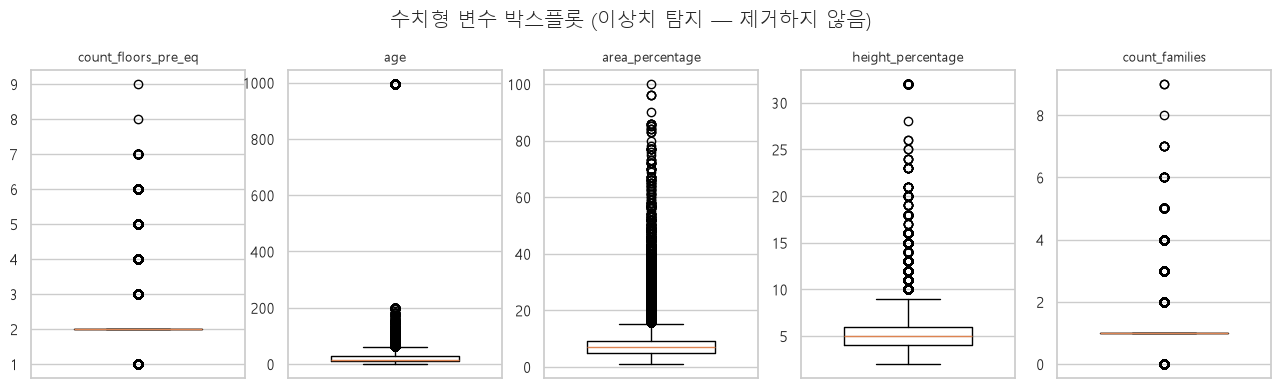

In [16]:
fig, axes = plt.subplots(1, len(NUM_COLS), figsize=(16, 4))
for ax, c in zip(axes, NUM_COLS):
    ax.boxplot(df[c], orientation="vertical", widths=0.6)
    ax.set_title(c, fontsize=9)
    ax.set_xticks([])
fig.suptitle("수치형 변수 박스플롯 (이상치 탐지 — 제거하지 않음)", y=1.03)
save_fig(fig, "outlier_boxplot")
plt.show()

In [17]:
# ============================================================
# §6. 수치형 변수 분포와 타깃 관계
# ============================================================
print(df[NUM_COLS].describe(percentiles=[.01, .25, .5, .75, .95, .99]).round(2).to_string())

       count_floors_pre_eq        age  area_percentage  height_percentage  count_families
count            208480.00  208480.00        208480.00          208480.00       208480.00
mean                  2.13      26.60             8.02               5.43            0.98
std                   0.73      73.97             4.42               1.92            0.42
min                   1.00       0.00             1.00               2.00            0.00
1%                    1.00       0.00             2.00               2.00            0.00
25%                   2.00      10.00             5.00               4.00            1.00
50%                   2.00      15.00             7.00               5.00            1.00
75%                   2.00      30.00             9.00               6.00            1.00
95%                   3.00      60.00            16.00               9.00            2.00
99%                   4.00     100.00            24.00              11.00            2.00
max       

[저장] C:\Users\jhj31\project_1\earthquake\outputs\t_project_v2\01_eda\figures\numeric_distribution.png


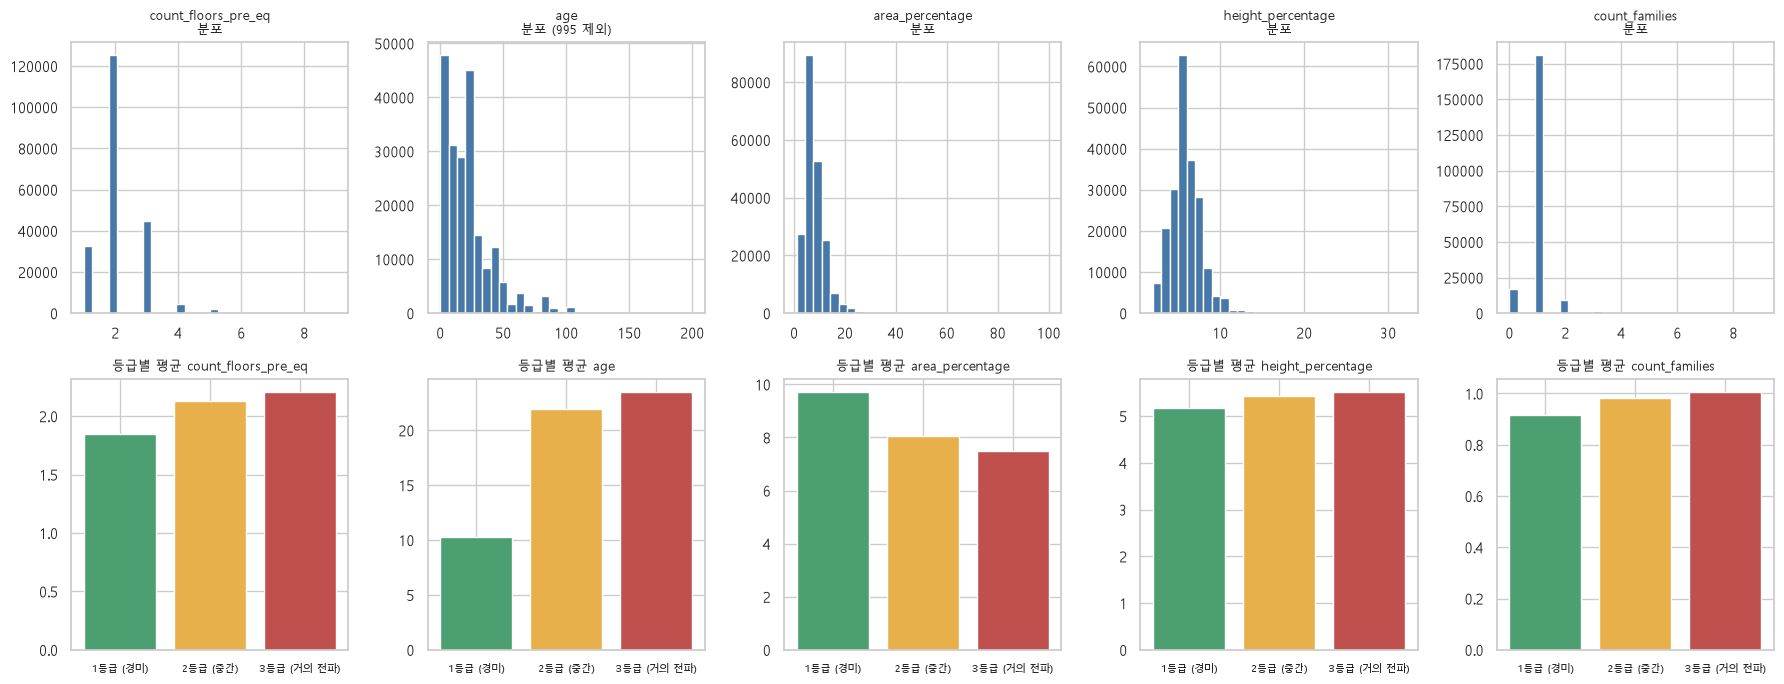

In [18]:
fig, axes = plt.subplots(2, len(NUM_COLS), figsize=(18, 7))
for i, c in enumerate(NUM_COLS):
    plot_data = df.loc[df["age"] != 995, c] if c == "age" else df[c]
    axes[0, i].hist(plot_data, bins=30, color="#4878A8", edgecolor="white")
    axes[0, i].set_title(f"{c}\n분포" + (" (995 제외)" if c == "age" else ""), fontsize=9)

    m = df.loc[df["age"] != 995] if c == "age" else df
    means = m.groupby(TARGET)[c].mean()
    axes[1, i].bar([GRADE_LABEL[k].replace("\n", " ") for k in means.index],
                   means.values, color=["#4C9F70", "#E8B04B", "#C0504D"])
    axes[1, i].set_title(f"등급별 평균 {c}", fontsize=9)
    axes[1, i].tick_params(axis="x", labelsize=7)
fig.tight_layout()
save_fig(fig, "numeric_distribution")
plt.show()

In [19]:
# ============================================================
# §7. 범주형 변수 분포와 타깃 교차
# ============================================================
for c in CAT_COLS:
    t = df.groupby(c)[TARGET].agg(건수="size", 평균등급="mean")
    t["비율(%)"] = (t["건수"] / len(df) * 100).round(1)
    t["3등급(%)"] = (df[df[TARGET] == 3].groupby(c).size() / t["건수"] * 100).round(1)
    t["평균등급"] = t["평균등급"].round(3)
    print(f"── {c} (고유값 {df[c].nunique()}개)")
    print(t[["건수", "비율(%)", "평균등급", "3등급(%)"]].sort_values("평균등급").to_string())
    print()

── land_surface_condition (고유값 3개)
                            건수  비율(%)   평균등급  3등급(%)
land_surface_condition                              
t                       173392   83.2  2.234    33.5
n                        28421   13.6  2.251    32.3
o                         6667    3.2  2.294    36.7

── foundation_type (고유값 5개)
                     건수  비율(%)   평균등급  3등급(%)
foundation_type                              
i                  8465    4.1  1.456     2.2
w                 12129    5.8  1.811    10.0
u                 11436    5.5  1.880    14.0
h                  1191    0.6  2.108    36.4
r                175259   84.1  2.330    37.9

── roof_type (고유값 3개)
               건수  비율(%)   평균등급  3등급(%)
roof_type                              
x           12976    6.2  1.573     4.5
n          146185   70.1  2.270    34.4
q           49319   23.7  2.319    38.3

── ground_floor_type (고유값 5개)
                       건수  비율(%)   평균등급  3등급(%)
ground_floor_type                              

── other_floor_type (고유값 4개)
                      건수  비율(%)   평균등급  3등급(%)
other_floor_type                              
s                   9622    4.6  1.605     5.7
j                  31907   15.3  2.047    26.8
x                  34735   16.7  2.296    37.6
q                 132216   63.4  2.315    36.0

── position (고유값 4개)
              건수  비율(%)   평균등급  3등급(%)
position                              
j          10646    5.1  2.156    28.0
o           1874    0.9  2.199    25.3
s         161689   77.6  2.229    32.7
t          34271   16.4  2.311    39.1

── plan_configuration (고유값 10개)
                        건수  비율(%)   평균등급  3등급(%)
plan_configuration                              
c                      265    0.1  1.811     9.1
a                      201    0.1  1.891    12.9
o                      130    0.1  1.900    16.2
u                     2947    1.4  1.925    13.4
m                       35    0.0  2.000    11.4
s                      280    0.1  2.046    20.7
n       

In [20]:
# 지배 범주 경고 — 한 범주가 95% 이상이면 변별력이 낮다
print("[지배 범주 점검] 최빈 범주가 전체의 몇 %를 차지하는가")
dom = pd.Series({c: df[c].value_counts(normalize=True).iloc[0] * 100 for c in CAT_COLS})
print(dom.round(1).sort_values(ascending=False).to_string())
print("\n→ 95%를 넘는 변수는 원핫 후 대부분의 열이 희소해진다. 인코딩 전략 검토 대상.")

[지배 범주 점검] 최빈 범주가 전체의 몇 %를 차지하는가


legal_ownership_status    96.3
plan_configuration        95.9
foundation_type           84.1
land_surface_condition    83.2
ground_floor_type         80.4
position                  77.6
roof_type                 70.1
other_floor_type          63.4

→ 95%를 넘는 변수는 원핫 후 대부분의 열이 희소해진다. 인코딩 전략 검토 대상.


In [21]:
# ============================================================
# §8. 상부구조 재료 분석 (핵심)
# ============================================================
print("=" * 60)
print("8-1. 재료별 사용률과 피해 프로필")
print("=" * 60)
rows = []
for c in SUPER_COLS:
    g = df.loc[df[c] == 1, TARGET]
    rows.append({"재료": c.replace("has_superstructure_", ""),
                 "사용 건물수": len(g), "사용률(%)": round(df[c].mean() * 100, 2),
                 "1등급%": round((g == 1).mean() * 100, 1),
                 "2등급%": round((g == 2).mean() * 100, 1),
                 "3등급%": round((g == 3).mean() * 100, 1),
                 "평균등급": round(g.mean(), 3)})
mat = pd.DataFrame(rows).sort_values("평균등급", ascending=False)
print(mat.to_string(index=False))
print(f"\n전체 평균등급 = {df[TARGET].mean():.3f}")

8-1. 재료별 사용률과 피해 프로필
                 재료  사용 건물수  사용률(%)  1등급%  2등급%  3등급%  평균등급
         stone_flag    7129    3.42   2.0  50.5  47.5 2.455
          adobe_mud   18529    8.89   2.6  60.0  37.4 2.348
   mud_mortar_stone  158774   76.16   4.4  57.4  38.2 2.338
   mud_mortar_brick   14276    6.85   3.5  65.8  30.8 2.273
             timber   53163   25.50  11.5  60.3  28.1 2.166
             bamboo   17783    8.53  12.8  63.3  23.9 2.111
              other    3121    1.50  17.2  57.5  25.3 2.080
cement_mortar_stone    3804    1.82  17.5  68.2  14.3 1.968
  rc_non_engineered    8922    4.28  34.7  52.5  12.8 1.782
cement_mortar_brick   15658    7.51  36.2  58.2   5.5 1.693
      rc_engineered    3300    1.58  64.4  33.8   1.9 1.375

전체 평균등급 = 2.238


In [22]:
# 복수 재료 사용 여부 — 단일 범주형으로 합치면 안 되는 근거
n_mat = df[SUPER_COLS].sum(axis=1)
print("[건물당 사용 재료 개수]")
print(n_mat.value_counts().sort_index().to_string())
print(f"\n2개 이상 사용: {(n_mat >= 2).mean()*100:.1f}%  → 단일 재료 변수로 변환 불가")

[건물당 사용 재료 개수]
1    140745
2     46318
3     16171
4      3963
5      1015
6       239
7        28
8         1

2개 이상 사용: 32.5%  → 단일 재료 변수로 변환 불가


[저장] C:\Users\jhj31\project_1\earthquake\outputs\t_project_v2\01_eda\figures\material_damage.png


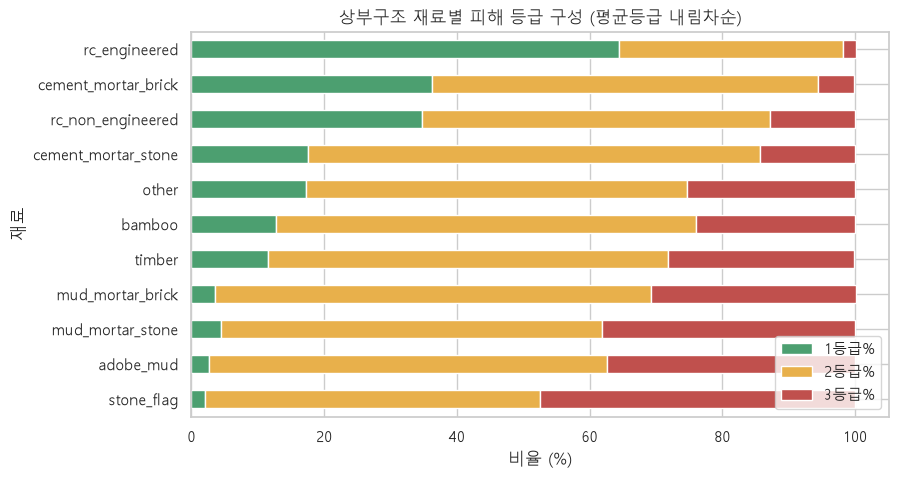

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = mat.set_index("재료")[["1등급%", "2등급%", "3등급%"]]
plot_df.plot(kind="barh", stacked=True, ax=ax,
             color=["#4C9F70", "#E8B04B", "#C0504D"])
ax.set_xlabel("비율 (%)")
ax.set_title("상부구조 재료별 피해 등급 구성 (평균등급 내림차순)")
ax.legend(loc="lower right")
save_fig(fig, "material_damage")
plt.show()

In [24]:
# ============================================================
# §9. 지역 코드 분석 — 이 데이터의 핵심 함정
# ============================================================
print("=" * 60)
print("9-1. 카디널리티")
print("=" * 60)
for c in GEO_COLS:
    print(f"{c:18s} 고유값 {df[c].nunique():6,}개   "
          f"원핫 시 생성될 열 수 {df[c].nunique():6,}")
print("""
→ geo_level_3는 원핫하면 열이 1만 개를 넘는다.
  선택지: ① level_1만 원핫 ② 빈도 인코딩 ③ 타깃 인코딩 ④ 수치형 그대로(트리 전용)
  ④는 '코드번호 ≤ 17' 같은 무의미한 분기를 만들지만 성능은 오른다.
  성능과 해석이 충돌하는 이 지점을 리포트에 기록할 것.
""")

9-1. 카디널리티
geo_level_1_id     고유값     31개   원핫 시 생성될 열 수     31
geo_level_2_id     고유값  1,408개   원핫 시 생성될 열 수  1,408
geo_level_3_id     고유값 11,353개   원핫 시 생성될 열 수 11,353

→ geo_level_3는 원핫하면 열이 1만 개를 넘는다.
  선택지: ① level_1만 원핫 ② 빈도 인코딩 ③ 타깃 인코딩 ④ 수치형 그대로(트리 전용)
  ④는 '코드번호 ≤ 17' 같은 무의미한 분기를 만들지만 성능은 오른다.
  성능과 해석이 충돌하는 이 지점을 리포트에 기록할 것.



In [25]:
print("=" * 60)
print("9-2. geo_level_1별 피해 — 지역 간 격차가 존재하는가")
print("=" * 60)
geo1 = df.groupby("geo_level_1_id").agg(
    건물수=(TARGET, "size"),
    평균등급=(TARGET, "mean"),
    진흙석재비율=("has_superstructure_mud_mortar_stone", "mean"),
    RC비율=("has_superstructure_rc_engineered", "mean"),
).round(3)
geo1 = geo1[geo1["건물수"] >= 1000].sort_values("평균등급")
print("── 피해가 적은 지역 5개")
print(geo1.head(5).to_string())
print("\n── 피해가 큰 지역 5개")
print(geo1.tail(5).to_string())
print(f"\n지역 간 평균등급 범위: {geo1['평균등급'].min():.3f} ~ {geo1['평균등급'].max():.3f}")


9-2. geo_level_1별 피해 — 지역 간 격차가 존재하는가
── 피해가 적은 지역 5개
                  건물수   평균등급  진흙석재비율   RC비율
geo_level_1_id                             
26              18038  1.729   0.461  0.035
24               1031  1.876   0.816  0.003
5                2190  1.926   0.925  0.004
20              13786  1.926   0.540  0.016
13               7754  1.947   0.943  0.003

── 피해가 큰 지역 5개
                  건물수   평균등급  진흙석재비율   RC비율
geo_level_1_id                             
27              10015  2.446   0.376  0.025
8               15331  2.487   0.906  0.013
21              11864  2.560   0.960  0.004
18               2530  2.712   0.704  0.013
17              17370  2.793   0.927  0.007

지역 간 평균등급 범위: 1.729 ~ 2.793


In [26]:
print("=" * 60)
print("9-3. 지역 효과는 재료 차이로 설명되는가?  ← 핵심 검정")
print("=" * 60)
corr = np.corrcoef(geo1["평균등급"], geo1["진흙석재비율"])[0, 1]
print(f"지역 평균등급 vs 진흙모르타르석재 비율 상관계수 = {corr:.3f}")

# 재료와 층수를 고정한 하위집단에서도 지역차가 남는지
sub = df[(df["has_superstructure_mud_mortar_stone"] == 1) &
         (df["count_floors_pre_eq"] == 2)]
s = (sub.groupby("geo_level_1_id")[TARGET]
        .agg(건물수="size", 평균등급="mean").round(3))
s = s[s["건물수"] >= 1000].sort_values("평균등급")
print(f"\n[통제 분석] 진흙모르타르석재 + 2층으로 고정 (n={len(sub):,})")
print("최저 3개 지역:"); print(s.head(3).to_string())
print("최고 3개 지역:"); print(s.tail(3).to_string())
print(f"\n통제 후에도 남은 지역 간 평균등급 범위 = {s['평균등급'].max() - s['평균등급'].min():.3f}")
print("""
[해석] 상관이 0에 가깝고 재료·층수를 통제해도 지역차가 그대로 남는다면,
       지역 코드는 '재료의 대리 변수'가 아니다.
       이 데이터에 없는 지진동 세기(진앙 거리·지반)의 대리 변수로 보는 것이 타당하다.
       → Ghimire(2022)가 MSI 중요도 31%, 진흙모르타르석재 32%로 보고한 것과 일치.
       → 전처리/모델링 단계에서 '지역 단위 그룹 분할'을 반드시 비교할 것.
          (같은 지역이 train/test에 섞이면 성능이 부풀려진다)
""")

9-3. 지역 효과는 재료 차이로 설명되는가?  ← 핵심 검정
지역 평균등급 vs 진흙모르타르석재 비율 상관계수 = -0.025

[통제 분석] 진흙모르타르석재 + 2층으로 고정 (n=104,523)
최저 3개 지역:
                 건물수   평균등급
geo_level_1_id             
5               1244  1.942
1               1468  1.943
13              4835  1.973
최고 3개 지역:
                 건물수   평균등급
geo_level_1_id             
21              4162  2.593
18              1101  2.826
17              8263  2.843

통제 후에도 남은 지역 간 평균등급 범위 = 0.901

[해석] 상관이 0에 가깝고 재료·층수를 통제해도 지역차가 그대로 남는다면,
       지역 코드는 '재료의 대리 변수'가 아니다.
       이 데이터에 없는 지진동 세기(진앙 거리·지반)의 대리 변수로 보는 것이 타당하다.
       → Ghimire(2022)가 MSI 중요도 31%, 진흙모르타르석재 32%로 보고한 것과 일치.
       → 전처리/모델링 단계에서 '지역 단위 그룹 분할'을 반드시 비교할 것.
          (같은 지역이 train/test에 섞이면 성능이 부풀려진다)



[저장] C:\Users\jhj31\project_1\earthquake\outputs\t_project_v2\01_eda\figures\geo_effect.png


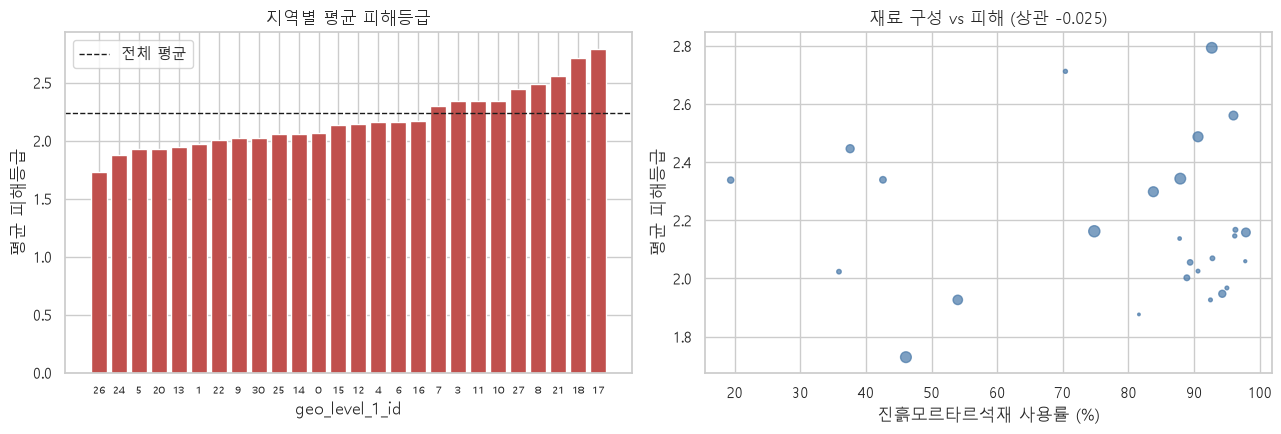

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(geo1.index.astype(str), geo1["평균등급"], color="#C0504D")
axes[0].axhline(df[TARGET].mean(), ls="--", c="k", lw=1, label="전체 평균")
axes[0].set_xlabel("geo_level_1_id"); axes[0].set_ylabel("평균 피해등급")
axes[0].set_title("지역별 평균 피해등급"); axes[0].legend()
axes[0].tick_params(axis="x", labelsize=7)

axes[1].scatter(geo1["진흙석재비율"] * 100, geo1["평균등급"],
                s=geo1["건물수"] / 300, alpha=0.7, color="#4878A8")
axes[1].set_xlabel("진흙모르타르석재 사용률 (%)"); axes[1].set_ylabel("평균 피해등급")
axes[1].set_title(f"재료 구성 vs 피해 (상관 {corr:.3f})")
fig.tight_layout()
save_fig(fig, "geo_effect")
plt.show()

In [28]:
# ============================================================
# §10. 희소 이진 변수 점검
# ============================================================
print("=" * 60)
print("10. has_secondary_use_* 희소성")
print("=" * 60)
rate = (df[SEC_COLS].mean() * 100).sort_values(ascending=False)
print(pd.DataFrame({"1의 비율(%)": rate.round(3),
                    "1의 건수": (df[SEC_COLS].sum()).reindex(rate.index)}).to_string())
rare = rate[rate < 0.5].index.tolist()
print(f"\n0.5% 미만인 변수 {len(rare)}개: {rare}")
print(f"이들을 모두 합쳐도 1인 건물은 {df[rare].max(axis=1).mean()*100:.2f}%")
print("""
[판단] 희소 플래그는 (a) 그대로 두기 (b) 하나로 통합 (c) 제거 중 선택.
       트리 모델은 희소 열에 거의 분기하지 않으므로 성능 영향은 작다.
       통합/제거를 택한다면 '성능 손실 없음'을 실험으로 보이고 근거를 남길 것.
""")

10. has_secondary_use_* 희소성
                               1의 비율(%)  1의 건수
has_secondary_use                11.179  23307
has_secondary_use_agriculture     6.401  13344
has_secondary_use_hotel           3.381   7049
has_secondary_use_rental          0.814   1696
has_secondary_use_other           0.512   1067
has_secondary_use_industry        0.104    217
has_secondary_use_institution     0.095    199
has_secondary_use_school          0.039     81
has_secondary_use_health_post     0.018     38
has_secondary_use_gov_office      0.015     32
has_secondary_use_use_police      0.010     20

0.5% 미만인 변수 6개: ['has_secondary_use_industry', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_secondary_use_use_police']
이들을 모두 합쳐도 1인 건물은 0.28%

[판단] 희소 플래그는 (a) 그대로 두기 (b) 하나로 통합 (c) 제거 중 선택.
       트리 모델은 희소 열에 거의 분기하지 않으므로 성능 영향은 작다.
       통합/제거를 택한다면 '성능 손실 없음'을 실험으로 보이고 근거를 남길 것.



In [29]:
# 플래그 일관성 — has_secondary_use와 세부 용도가 모순되는가
detail = [c for c in SEC_COLS if c != "has_secondary_use"]
incons_a = ((df["has_secondary_use"] == 0) & (df[detail].sum(axis=1) > 0)).sum()
incons_b = ((df["has_secondary_use"] == 1) & (df[detail].sum(axis=1) == 0)).sum()
print(f"[일관성] 상위=0 인데 세부=1 : {incons_a:,}건")
print(f"[일관성] 상위=1 인데 세부=0 : {incons_b:,}건  (기타 용도 미기재일 수 있음)")

[일관성] 상위=0 인데 세부=1 : 0건
[일관성] 상위=1 인데 세부=0 : 0건  (기타 용도 미기재일 수 있음)


In [30]:
# ============================================================
# §11. 변수-타깃 연관성 사전 탐색
# ============================================================
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder

print("상호정보량(mutual information) 계산 — 5만 건 표본")
samp = df.sample(50_000, random_state=RANDOM_STATE)
X_mi = samp[FEATURE_COLS].copy()
X_mi[CAT_COLS] = OrdinalEncoder().fit_transform(X_mi[CAT_COLS].astype(str))
discrete = [c not in NUM_COLS for c in FEATURE_COLS]

mi = mutual_info_classif(X_mi, samp[TARGET], discrete_features=discrete,
                         random_state=RANDOM_STATE)
mi_s = pd.Series(mi, index=FEATURE_COLS).sort_values(ascending=False)
print("\n[상위 15개]")
print(mi_s.head(15).round(4).to_string())
print("\n[하위 10개]")
print(mi_s.tail(10).round(4).to_string())
print("\n※ 상호정보량은 단변량 지표다. 모델의 feature importance와 다를 수 있다.")

상호정보량(mutual information) 계산 — 5만 건 표본



[상위 15개]
geo_level_3_id                            0.4316
geo_level_2_id                            0.2566
geo_level_1_id                            0.1306
foundation_type                           0.0713
ground_floor_type                         0.0535
has_superstructure_mud_mortar_stone       0.0489
other_floor_type                          0.0465
roof_type                                 0.0399
age                                       0.0344
has_superstructure_cement_mortar_brick    0.0322
count_floors_pre_eq                       0.0263
height_percentage                         0.0168
area_percentage                           0.0150
has_superstructure_rc_engineered          0.0146
has_superstructure_rc_non_engineered      0.0131

[하위 10개]
has_secondary_use_agriculture    0.0014
land_surface_condition           0.0009
has_superstructure_other         0.0008
has_secondary_use_institution    0.0005
has_secondary_use_industry       0.0002
has_secondary_use_gov_office     0.0002
has_s

[저장] C:\Users\jhj31\project_1\earthquake\outputs\t_project_v2\01_eda\figures\eda_result.png


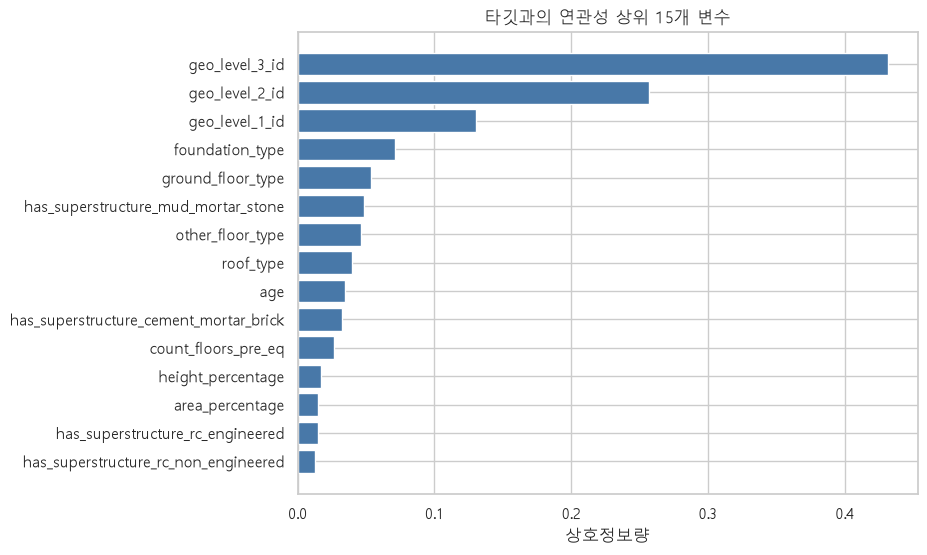

In [31]:
fig, ax = plt.subplots(figsize=(8, 6))
top = mi_s.head(15).sort_values()
ax.barh(top.index, top.values, color="#4878A8")
ax.set_xlabel("상호정보량")
ax.set_title("타깃과의 연관성 상위 15개 변수")
save_fig(fig, "eda_result")
plt.show()

In [32]:
# ============================================================
# §12. EDA 요약
# ============================================================
print("=" * 70)
print("EDA 요약")
print("=" * 70)
summary = pd.DataFrame([
    ["데이터 규모", f"{len(df):,}행 × {df.shape[1]}컬럼 (입력 38 / ID 1 / 타깃 1)"],
    ["결측치", f"NaN {int(df.isna().sum().sum())}개 — 대치 불필요"],
    ["의미론적 결측", f"age=995 {int((df['age']==995).sum()):,}건 — 코드값 의심, 플래그+NaN 권장"],
    ["ID 중복", f"{int(df[ID_COL].duplicated().sum())}건"],
    ["속성 중복", f"{int(feat_dup_mask.sum()):,}건 — 동일 유형의 다른 건물, 제거하지 않음"],
    ["모순 라벨", f"{int(irreducible.sum()):,}건 → 이론적 정확도 상한 약 {100-irreducible.sum()/len(df)*100:.1f}%"],
    ["이상치", "IQR 기준 다수 탐지되나 도메인상 실재 — 본 노트북에서 제거 없음"],
    ["클래스 불균형", f"{vc[1]/len(df)*100:.1f} / {vc[2]/len(df)*100:.1f} / {vc[3]/len(df)*100:.1f} (%) — 최빈 정확도 {vc.max()/len(df):.3f}"],
    ["최강 신호", f"{mi_s.index[0]} (MI {mi_s.iloc[0]:.3f})"],
    ["핵심 리스크", "지역 코드 의존 — 신규 지역 일반화 검증 필수"],
], columns=["항목", "결과"])
print(summary.to_string(index=False))

print("""
────────────────────────────────────────────────────────────────
다음 노트북(02_preprocessing)에서 결정할 것
  1. geo_level_2/3 인코딩 방식  (원핫 / 빈도 / 타깃 / 수치형)
  2. age=995 처리              (유지 / NaN+플래그 / 캡)
  3. 희소 플래그 처리           (유지 / 통합 / 제거)
  4. 분할 전략                  (무작위 층화 + 지역 그룹 분할 병행)
     ※ 모든 전처리는 분할 '이후' 학습셋 기준으로 fit 할 것
────────────────────────────────────────────────────────────────
""")

EDA 요약
     항목                                     결과
 데이터 규모  208,480행 × 40컬럼 (입력 38 / ID 1 / 타깃 1)
    결측치                        NaN 0개 — 대치 불필요
의미론적 결측    age=995 1,125건 — 코드값 의심, 플래그+NaN 권장
  ID 중복                                     0건
  속성 중복        19,592건 — 동일 유형의 다른 건물, 제거하지 않음
  모순 라벨            2,826건 → 이론적 정확도 상한 약 98.6%
    이상치 IQR 기준 다수 탐지되나 도메인상 실재 — 본 노트북에서 제거 없음
클래스 불균형   9.6 / 56.9 / 33.5 (%) — 최빈 정확도 0.569
  최강 신호              geo_level_3_id (MI 0.432)
 핵심 리스크             지역 코드 의존 — 신규 지역 일반화 검증 필수

────────────────────────────────────────────────────────────────
다음 노트북(02_preprocessing)에서 결정할 것
  1. geo_level_2/3 인코딩 방식  (원핫 / 빈도 / 타깃 / 수치형)
  2. age=995 처리              (유지 / NaN+플래그 / 캡)
  3. 희소 플래그 처리           (유지 / 통합 / 제거)
  4. 분할 전략                  (무작위 층화 + 지역 그룹 분할 병행)
     ※ 모든 전처리는 분할 '이후' 학습셋 기준으로 fit 할 것
────────────────────────────────────────────────────────────────

